In [1]:

import numpy as np
import pandas as pd


In [2]:

np.random.seed(42)

SCENARIOS = {
    "E-commerce":      {"amount": (10000, 200000),   "tenure": (3, 24),  "n": 80000},
    "Home_Appliances": {"amount": (20000, 300000),   "tenure": (6, 36),  "n": 80000},
    "Vehicle":         {"amount": (80000, 1500000),  "tenure": (12, 84), "n": 80000},
    "Personal_Loan":   {"amount": (50000, 1000000),  "tenure": (12, 60), "n": 80000},
    "Education":       {"amount": (50000, 500000),   "tenure": (6, 48),  "n": 80000},
}

def generate_scenario(scenario_name, cfg):
    n = cfg["n"]
    df = pd.DataFrame()

    df["age"] = np.random.randint(25, 61, n)
    df["gender"] = np.random.choice(["Male", "Female"], n)
    df["marital_status"] = np.random.choice(["Single", "Married"], n, p=[0.4, 0.6])
    df["education"] = np.random.choice(["High School", "Graduate", "Post Graduate", "Professional"], n, p=[0.15, 0.4, 0.3, 0.15])

    df["monthly_salary"] = np.random.randint(15000, 200001, n)
    df["employment_type"] = np.random.choice(["Private", "Government", "Self-employed"], n, p=[0.55, 0.25, 0.2])
    df["years_of_employment"] = np.random.randint(0, 35, n)
    df["company_type"] = np.random.choice(["Startup", "SME", "MNC", "Government"], n)

    df["house_type"] = np.random.choice(["Rented", "Own", "Family"], n, p=[0.4, 0.35, 0.25])
    df["monthly_rent"] = np.where(df["house_type"] == "Rented", np.random.randint(3000, 40000, n), 0)
    df["family_size"] = np.random.randint(1, 8, n)
    df["dependents"] = np.random.randint(0, 5, n)

    df["school_fees"] = np.random.randint(0, 15000, n)
    df["college_fees"] = np.random.randint(0, 25000, n)
    df["travel_expenses"] = np.random.randint(500, 10000, n)
    df["groceries_utilities"] = np.random.randint(2000, 25000, n)
    df["other_monthly_expenses"] = np.random.randint(500, 15000, n)

    df["existing_loans"] = np.random.choice(["Yes", "No"], n, p=[0.4, 0.6])
    df["current_emi_amount"] = np.where(df["existing_loans"] == "Yes", np.random.randint(1000, 30000, n), 0)
    df["credit_score"] = np.random.randint(300, 851, n)
    df["bank_balance"] = np.random.randint(0, 500000, n)
    df["emergency_fund"] = np.random.randint(0, 200000, n)

    df["emi_scenario"] = scenario_name
    df["requested_amount"] = np.random.randint(cfg["amount"][0], cfg["amount"][1] + 1, n)
    df["requested_tenure"] = np.random.randint(cfg["tenure"][0], cfg["tenure"][1] + 1, n)

    total_expenses = (df["monthly_rent"] + df["school_fees"] + df["college_fees"] +
                       df["travel_expenses"] + df["groceries_utilities"] +
                       df["other_monthly_expenses"] + df["current_emi_amount"])
    disposable_income = df["monthly_salary"] - total_expenses
    credit_factor = (df["credit_score"] - 300) / 550

    raw_max_emi = np.clip(disposable_income * (0.3 + 0.3 * credit_factor), 0, None)
    df["max_monthly_emi"] = np.clip(raw_max_emi, 500, 50000).round(0)

    implied_emi_for_request = df["requested_amount"] / df["requested_tenure"]
    affordability_ratio = df["max_monthly_emi"] / (implied_emi_for_request + 1)

    def classify(row_ratio, score):
        if row_ratio >= 1.0 and score >= 650:
            return "Eligible"
        elif row_ratio >= 0.6 or score >= 550:
            return "High_Risk"
        else:
            return "Not_Eligible"

    df["emi_eligibility"] = [classify(r, s) for r, s in zip(affordability_ratio, df["credit_score"])]
    return df

all_dfs = [generate_scenario(name, cfg) for name, cfg in SCENARIOS.items()]
df = pd.concat(all_dfs, ignore_index=True)
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

n_missing = int(0.01 * len(df))
missing_idx = np.random.choice(df.index, n_missing, replace=False)
df.loc[missing_idx, "monthly_salary"] = np.nan

dup_sample = df.sample(200, random_state=1)
df = pd.concat([df, dup_sample], ignore_index=True)

df.to_csv("emi_dataset.csv", index=False)
df.shape


(400200, 27)

In [3]:

df = pd.read_csv("emi_dataset.csv")
df.shape


(400200, 27)

In [4]:

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400200 entries, 0 to 400199
Data columns (total 27 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   age                     400200 non-null  int64  
 1   gender                  400200 non-null  object 
 2   marital_status          400200 non-null  object 
 3   education               400200 non-null  object 
 4   monthly_salary          396199 non-null  float64
 5   employment_type         400200 non-null  object 
 6   years_of_employment     400200 non-null  int64  
 7   company_type            400200 non-null  object 
 8   house_type              400200 non-null  object 
 9   monthly_rent            400200 non-null  int64  
 10  family_size             400200 non-null  int64  
 11  dependents              400200 non-null  int64  
 12  school_fees             400200 non-null  int64  
 13  college_fees            400200 non-null  int64  
 14  travel_expenses     

In [5]:

df.isnull().sum()


age                          0
gender                       0
marital_status               0
education                    0
monthly_salary            4001
employment_type              0
years_of_employment          0
company_type                 0
house_type                   0
monthly_rent                 0
family_size                  0
dependents                   0
school_fees                  0
college_fees                 0
travel_expenses              0
groceries_utilities          0
other_monthly_expenses       0
existing_loans               0
current_emi_amount           0
credit_score                 0
bank_balance                 0
emergency_fund               0
emi_scenario                 0
requested_amount             0
requested_tenure             0
max_monthly_emi              0
emi_eligibility              0
dtype: int64

In [6]:

df.duplicated().sum()


np.int64(200)

In [7]:

df.describe(include="all")


,age,gender,marital_status,education,monthly_salary,employment_type,years_of_employment,company_type,house_type,monthly_rent,...,existing_loans,current_emi_amount,credit_score,bank_balance,emergency_fund,emi_scenario,requested_amount,requested_tenure,max_monthly_emi,emi_eligibility
count,400200.000000,400200,400200,400200,396199.000000,400200,400200.000000,400200,400200,400200.000000,...,400200,400200.000000,400200.000000,400200.000000,400200.000000,400200,4.002000e+05,400200.000000,400200.000000,400200
unique,NaN,2,2,4,NaN,3,NaN,4,3,NaN,...,2,NaN,NaN,NaN,NaN,5,NaN,NaN,NaN,3
top,NaN,Male,Married,Graduate,NaN,Private,NaN,Government,Rented,NaN,...,No,NaN,NaN,NaN,NaN,Personal_Loan,NaN,NaN,NaN,High_Risk
freq,NaN,200177,240300,160179,NaN,220480,NaN,100366,160128,NaN,...,239699,NaN,NaN,NaN,NaN,80049,NaN,NaN,NaN,243503
mean,42.492454,NaN,NaN,NaN,107598.653664,NaN,17.009193,NaN,NaN,8596.518326,...,NaN,6200.261987,574.831992,250197.586224,99859.368316,NaN,3.707187e+05,29.063636,22158.265207,NaN
std,10.383264,NaN,NaN,NaN,53373.976068,NaN,10.105803,NaN,NaN,12507.716730,...,NaN,9250.177625,159.102479,144361.591981,57761.562392,NaN,3.439262e+05,18.058004,18852.826673,NaN
min,25.000000,NaN,NaN,NaN,15000.000000,NaN,0.000000,NaN,NaN,0.000000,...,NaN,0.000000,300.000000,3.000000,0.000000,NaN,1.000200e+04,3.000000,500.000000,NaN
25%,33.000000,NaN,NaN,NaN,61404.000000,NaN,8.000000,NaN,NaN,0.000000,...,NaN,0.000000,437.000000,125251.000000,49707.750000,NaN,1.246540e+05,15.000000,500.000000,NaN
50%,42.000000,NaN,NaN,NaN,107680.000000,NaN,17.000000,NaN,NaN,0.000000,...,NaN,0.000000,575.000000,249921.500000,99848.000000,NaN,2.371160e+05,24.000000,20071.000000,NaN
75%,51.000000,NaN,NaN,NaN,153854.500000,NaN,26.000000,NaN,NaN,16865.250000,...,NaN,11860.000000,713.000000,375205.250000,149803.250000,NaN,4.949192e+05,40.000000,40345.000000,NaN


In [8]:

df["emi_eligibility"].value_counts(normalize=True)


emi_eligibility
High_Risk       0.608453
Eligible        0.218476
Not_Eligible    0.173071
Name: proportion, dtype: float64

In [9]:

df["max_monthly_emi"].describe()


count    400200.000000
mean      22158.265207
std       18852.826673
min         500.000000
25%         500.000000
50%       20071.000000
75%       40345.000000
max       50000.000000
Name: max_monthly_emi, dtype: float64

In [10]:

df.groupby("emi_scenario")["emi_eligibility"].value_counts(normalize=True)


emi_scenario     emi_eligibility
E-commerce       High_Risk          0.610448
                 Eligible           0.234978
                 Not_Eligible       0.154574
Education        High_Risk          0.608653
                 Eligible           0.221792
                 Not_Eligible       0.169555
Home_Appliances  High_Risk          0.609131
                 Eligible           0.236678
                 Not_Eligible       0.154191
Personal_Loan    High_Risk          0.606391
                 Eligible           0.208984
                 Not_Eligible       0.184624
Vehicle          High_Risk          0.607643
                 Not_Eligible       0.202406
                 Eligible           0.189950
Name: proportion, dtype: float64

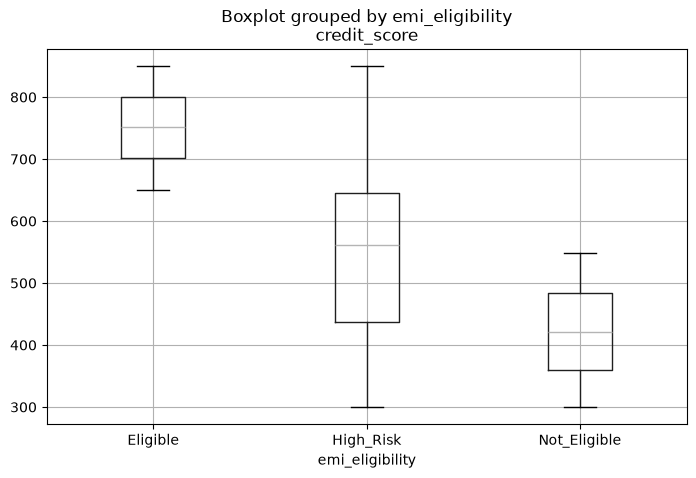

In [11]:

import matplotlib.pyplot as plt

df.boxplot(column="credit_score", by="emi_eligibility", figsize=(8, 5))
plt.show()


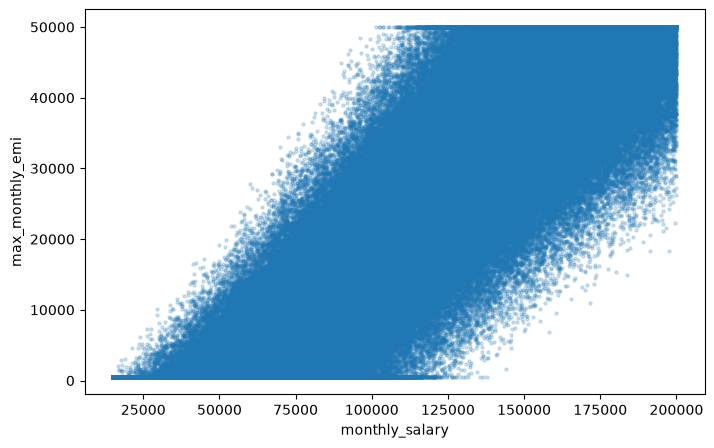

In [12]:

plt.figure(figsize=(8, 5))
plt.scatter(df["monthly_salary"], df["max_monthly_emi"], alpha=0.2, s=5)
plt.xlabel("monthly_salary")
plt.ylabel("max_monthly_emi")
plt.show()


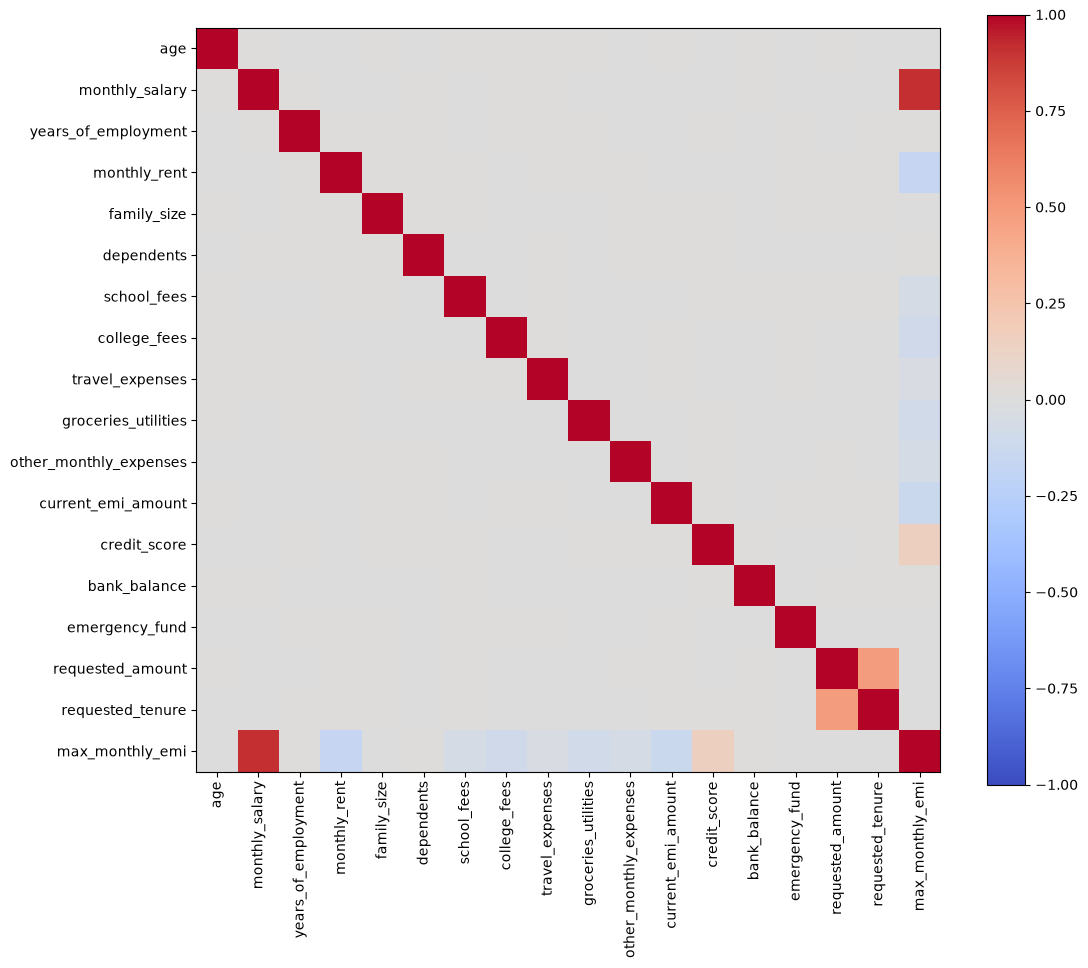

In [13]:

numeric_df = df.select_dtypes(include=np.number)
corr = numeric_df.corr()

plt.figure(figsize=(12, 10))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.show()


In [14]:

def clean_data(df):
    df = df.copy()
    df = df.drop_duplicates()

    for col in df.select_dtypes(include=np.number).columns:
        if df[col].isnull().any():
            df[col] = df[col].fillna(df[col].median())

    for col in df.select_dtypes(include="object").columns:
        if df[col].isnull().any():
            df[col] = df[col].fillna(df[col].mode()[0])

    df["age"] = df["age"].clip(25, 60)
    df["credit_score"] = df["credit_score"].clip(300, 850)
    df["monthly_salary"] = df["monthly_salary"].clip(lower=0)
    return df

df = clean_data(df)
df.isnull().sum().sum()


np.int64(0)

In [15]:

def engineer_features(df):
    df = df.copy()
    salary = df["monthly_salary"].replace(0, 1)

    total_expenses = (df["monthly_rent"] + df["school_fees"] + df["college_fees"] +
                       df["travel_expenses"] + df["groceries_utilities"] +
                       df["other_monthly_expenses"])

    df["debt_to_income"] = df["current_emi_amount"] / salary
    df["expense_to_income"] = total_expenses / salary
    df["savings_ratio"] = df["bank_balance"] / salary
    df["loan_to_income"] = df["requested_amount"] / salary

    disposable = salary - total_expenses - df["current_emi_amount"]
    df["affordability_ratio"] = disposable / (df["requested_amount"] / df["requested_tenure"].replace(0, 1) + 1)
    return df

df = engineer_features(df)
df.head()


,age,gender,marital_status,education,monthly_salary,employment_type,years_of_employment,company_type,house_type,monthly_rent,...,emi_scenario,requested_amount,requested_tenure,max_monthly_emi,emi_eligibility,debt_to_income,expense_to_income,savings_ratio,loan_to_income,affordability_ratio
0,49,Male,Married,Professional,107819.0,Private,8,Startup,Rented,19006,...,E-commerce,17841,14,12954.0,High_Risk,0.208627,0.513963,1.405161,0.165472,23.452254
1,25,Female,Married,Graduate,17174.0,Self-employed,30,Government,Rented,33333,...,E-commerce,63526,12,500.0,Not_Eligible,0.543147,4.169850,8.708746,3.698964,-12.043250
2,43,Male,Single,High School,197437.0,Private,27,Government,Rented,18866,...,E-commerce,133258,20,50000.0,High_Risk,0.000000,0.281340,0.224882,0.674939,21.292336
3,46,Female,Married,Post Graduate,120058.0,Private,34,Government,Family,0,...,Home_Appliances,279058,10,27909.0,High_Risk,0.017483,0.491529,2.097211,2.324360,2.112281
4,31,Female,Single,Graduate,148448.0,Government,20,Government,Family,0,...,Personal_Loan,422780,36,35011.0,High_Risk,0.000000,0.259613,2.209764,2.848001,9.358028


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, LabelEncoder

NUMERIC_FEATURES = [
    "age", "monthly_salary", "years_of_employment", "monthly_rent",
    "family_size", "dependents", "school_fees", "college_fees",
    "travel_expenses", "groceries_utilities", "other_monthly_expenses",
    "current_emi_amount", "credit_score", "bank_balance", "emergency_fund",
    "requested_amount", "requested_tenure",
    "debt_to_income", "expense_to_income", "affordability_ratio",
    "savings_ratio", "loan_to_income",
]

CATEGORICAL_FEATURES = [
    "gender", "marital_status", "employment_type", "company_type",
    "house_type", "existing_loans", "emi_scenario",
]

ORDINAL_FEATURES = ["education"]
EDUCATION_ORDER = ["High School", "Graduate", "Post Graduate", "Professional"]

def build_preprocessor():
    return ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), NUMERIC_FEATURES),
            ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
            ("ord", OrdinalEncoder(categories=[EDUCATION_ORDER]), ORDINAL_FEATURES),
        ],
        remainder="drop",
    )


In [ ]:

FEATURE_COLS = [c for c in df.columns if c not in ("emi_eligibility", "max_monthly_emi")]
X = df[FEATURE_COLS]

label_encoder = LabelEncoder()
y_clf = pd.Series(label_encoder.fit_transform(df["emi_eligibility"]), index=df.index)
y_reg = df["max_monthly_emi"]

X_train, X_test, yclf_train, yclf_test, yreg_train, yreg_test = train_test_split(
    X, y_clf, y_reg, test_size=0.2, random_state=42, stratify=y_clf
)

X_train.shape, X_test.shape


In [ ]:
import mlflow
import mlflow.sklearn

mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("EMIPredict_AI")

In [ ]:

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import joblib

classifiers = {
    "logistic_regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "random_forest_clf": RandomForestClassifier(n_estimators=200, max_depth=12, class_weight="balanced", n_jobs=-1, random_state=42),
    "xgboost_clf": XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1, eval_metric="mlogloss", random_state=42),
}

best_clf_score = -1
best_clf_name = None
best_clf_pipe = None

for name, model in classifiers.items():
    with mlflow.start_run(run_name=name):
        pipe = Pipeline([("preprocess", build_preprocessor()), ("model", model)])
        pipe.fit(X_train, yclf_train)

        y_pred = pipe.predict(X_test)
        y_proba = pipe.predict_proba(X_test)

        acc = accuracy_score(yclf_test, y_pred)
        prec = precision_score(yclf_test, y_pred, average="macro")
        rec = recall_score(yclf_test, y_pred, average="macro")
        f1 = f1_score(yclf_test, y_pred, average="macro")
        auc = roc_auc_score(yclf_test, y_proba, multi_class="ovr")

        mlflow.log_param("model_type", name)
        mlflow.log_metric("accuracy", acc)
        mlflow.log_metric("precision_macro", prec)
        mlflow.log_metric("recall_macro", rec)
        mlflow.log_metric("f1_macro", f1)
        mlflow.log_metric("roc_auc_ovr", auc)
        mlflow.sklearn.log_model(pipe, "model", serialization_format="cloudpickle")

        print(name, acc, f1, auc)

        if f1 > best_clf_score:
            best_clf_score = f1
            best_clf_name = name
            best_clf_pipe = pipe

joblib.dump(best_clf_pipe, "best_classifier.pkl")
joblib.dump(label_encoder, "label_encoder.pkl")
best_clf_name, best_clf_score


2026/09/04 10:36:49 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/09/04 10:36:49 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


In [ ]:

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

regressors = {
    "linear_regression": LinearRegression(),
    "random_forest_reg": RandomForestRegressor(n_estimators=200, max_depth=12, n_jobs=-1, random_state=42),
    "xgboost_reg": XGBRegressor(n_estimators=200, max_depth=6, learning_rate=0.1, random_state=42),
}

best_reg_score = np.inf
best_reg_name = None
best_reg_pipe = None

for name, model in regressors.items():
    with mlflow.start_run(run_name=name):
        pipe = Pipeline([("preprocess", build_preprocessor()), ("model", model)])
        pipe.fit(X_train, yreg_train)

        y_pred = pipe.predict(X_test)
        rmse = np.sqrt(mean_squared_error(yreg_test, y_pred))
        mae = mean_absolute_error(yreg_test, y_pred)
        r2 = r2_score(yreg_test, y_pred)
        mape = np.mean(np.abs((yreg_test - y_pred) / yreg_test.replace(0, 1))) * 100

        mlflow.log_param("model_type", name)
        mlflow.log_metric("rmse", rmse)
        mlflow.log_metric("mae", mae)
        mlflow.log_metric("r2", r2)
        mlflow.log_metric("mape", mape)
        mlflow.sklearn.log_model(pipe, "model", serialization_format="cloudpickle")

        print(name, rmse, mae, r2)

        if rmse < best_reg_score:
            best_reg_score = rmse
            best_reg_name = name
            best_reg_pipe = pipe

joblib.dump(best_reg_pipe, "best_regressor.pkl")
best_reg_name, best_reg_score


In [ ]:

clf = joblib.load("best_classifier.pkl")
reg = joblib.load("best_regressor.pkl")
le = joblib.load("label_encoder.pkl")

sample = X_test.head(5)
pred_clf = clf.predict(sample)
pred_reg = reg.predict(sample)

pd.DataFrame({
    "predicted_eligibility": le.inverse_transform(pred_clf),
    "predicted_max_emi": pred_reg
})
